In [ ]:
!pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (5).zip to archive (5).zip


In [ ]:
import os
import zipfile
import pandas as pd

uploaded_file = list(uploaded.keys())[0]

if uploaded_file.lower().endswith('.zip'):
    extract_path = "/content/rice_data"

    with zipfile.ZipFile(uploaded_file, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    data_files = []
    for root, dirs, filenames in os.walk(extract_path):
        for file in filenames:
            ext = file.lower()
            if ext.endswith('.csv') or ext.endswith('.xlsx') or ext.endswith('.xls'):
                data_files.append(os.path.join(root, file))

    if not data_files:
        raise Exception("No CSV or Excel file found inside ZIP!")

    data_path = data_files[0]

elif uploaded_file.lower().endswith(('.csv', '.xlsx', '.xls')):
    data_path = uploaded_file

else:
    raise Exception("Please upload a ZIP, CSV, or Excel file!")

if data_path.lower().endswith('.csv'):
    df = pd.read_csv(data_path)
else:
    df = pd.read_excel(data_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class'])
y = df['Class']

encoder = LabelEncoder()
y = encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data preprocessing completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Rice varieties:", encoder.classes_)

Data preprocessing completed!
Training samples: 3048
Testing samples: 762
Number of features: 7
Rice varieties: ['Cammeo' 'Osmancik']


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

model = Sequential([

    Input(shape=(7,)),

    Dense(64, activation='relu'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(2, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,154 (12.32 KB)

 Trainable params: 3,154 (12.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9352 - loss: 0.1736 - val_accuracy: 0.9180 - val_loss: 0.2295
Epoch 2/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9368 - loss: 0.1738 - val_accuracy: 0.9180 - val_loss: 0.2258
Epoch 3/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9364 - loss: 0.1703 - val_accuracy: 0.9180 - val_loss: 0.2225
Epoch 4/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9311 - loss: 0.1730 - val_accuracy: 0.9164 - val_loss: 0.2213
Epoch 5/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9340 - loss: 0.1775 - val_accuracy: 0.9164 - val_loss: 0.2238
Epoch 6/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9352 - loss: 0.1719 - val_accuracy: 0.9180 - val_loss: 0.2247
Epoch 7/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9336 - loss: 0.1728 - val_accuracy: 0.9180 - val_loss: 0.2300
Epoch 8/15
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9336 - loss: 0.1718 - val_accuracy: 0.9164 - val_lo

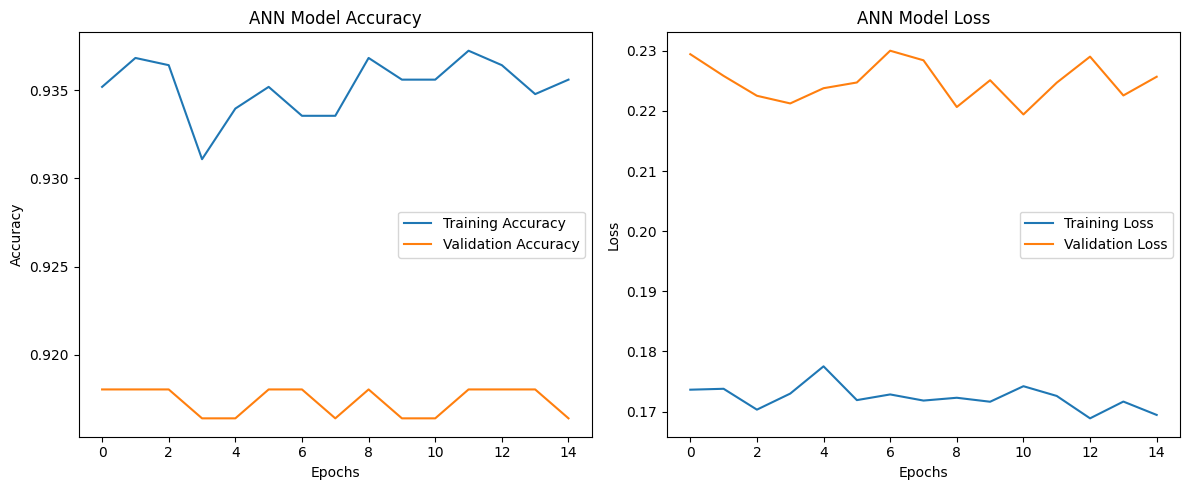

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", loss)

print("Testing Accuracy:",
      round(accuracy * 100, 2), "%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9173 - loss: 0.2001
Testing Loss: 0.20013096928596497
Testing Accuracy: 91.73 %


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


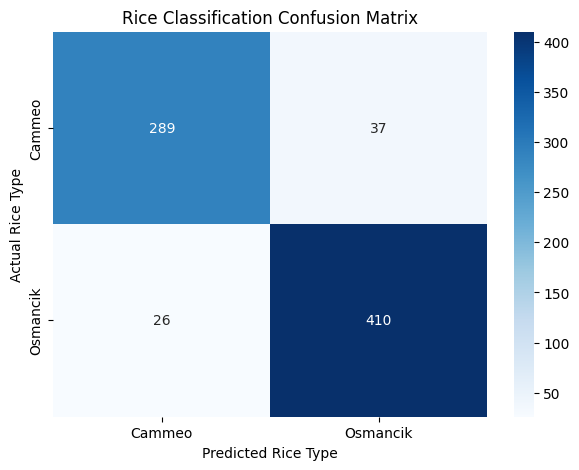

              precision    recall  f1-score   support

      Cammeo       0.92      0.89      0.90       326
    Osmancik       0.92      0.94      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.92       762
weighted avg       0.92      0.92      0.92       762



In [ ]:
import numpy as np
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Rice Type")
plt.ylabel("Actual Rice Type")
plt.title("Rice Classification Confusion Matrix")

plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

In [ ]:
sample = X_test[0].reshape(1, -1)

prediction = model.predict(sample)

predicted_index = np.argmax(prediction[0])

predicted_rice = encoder.inverse_transform(
    [predicted_index]
)[0]

actual_rice = encoder.inverse_transform(
    [y_test[0]]
)[0]

print("Actual Rice Type:", actual_rice)
print("Predicted Rice Type:", predicted_rice)

print("Prediction Confidence:",
      round(float(np.max(prediction[0])) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Actual Rice Type: Cammeo
Predicted Rice Type: Cammeo
Prediction Confidence: 97.62 %


In [ ]:
model.save("/content/Rice_Type_Classification.keras")

print("Model saved successfully!")

Model saved successfully!


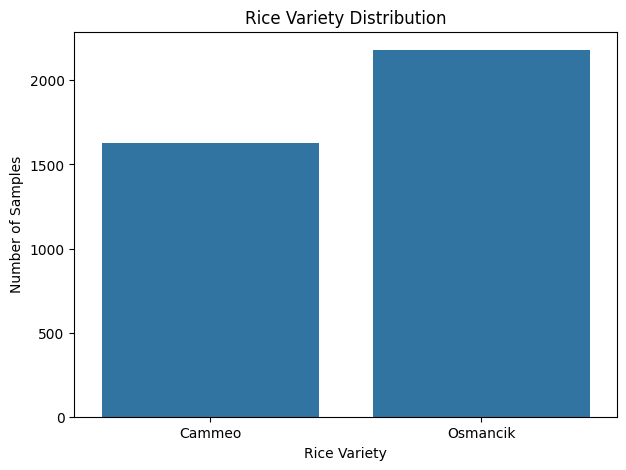

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Class')

plt.title('Rice Variety Distribution')
plt.xlabel('Rice Variety')
plt.ylabel('Number of Samples')

plt.show()

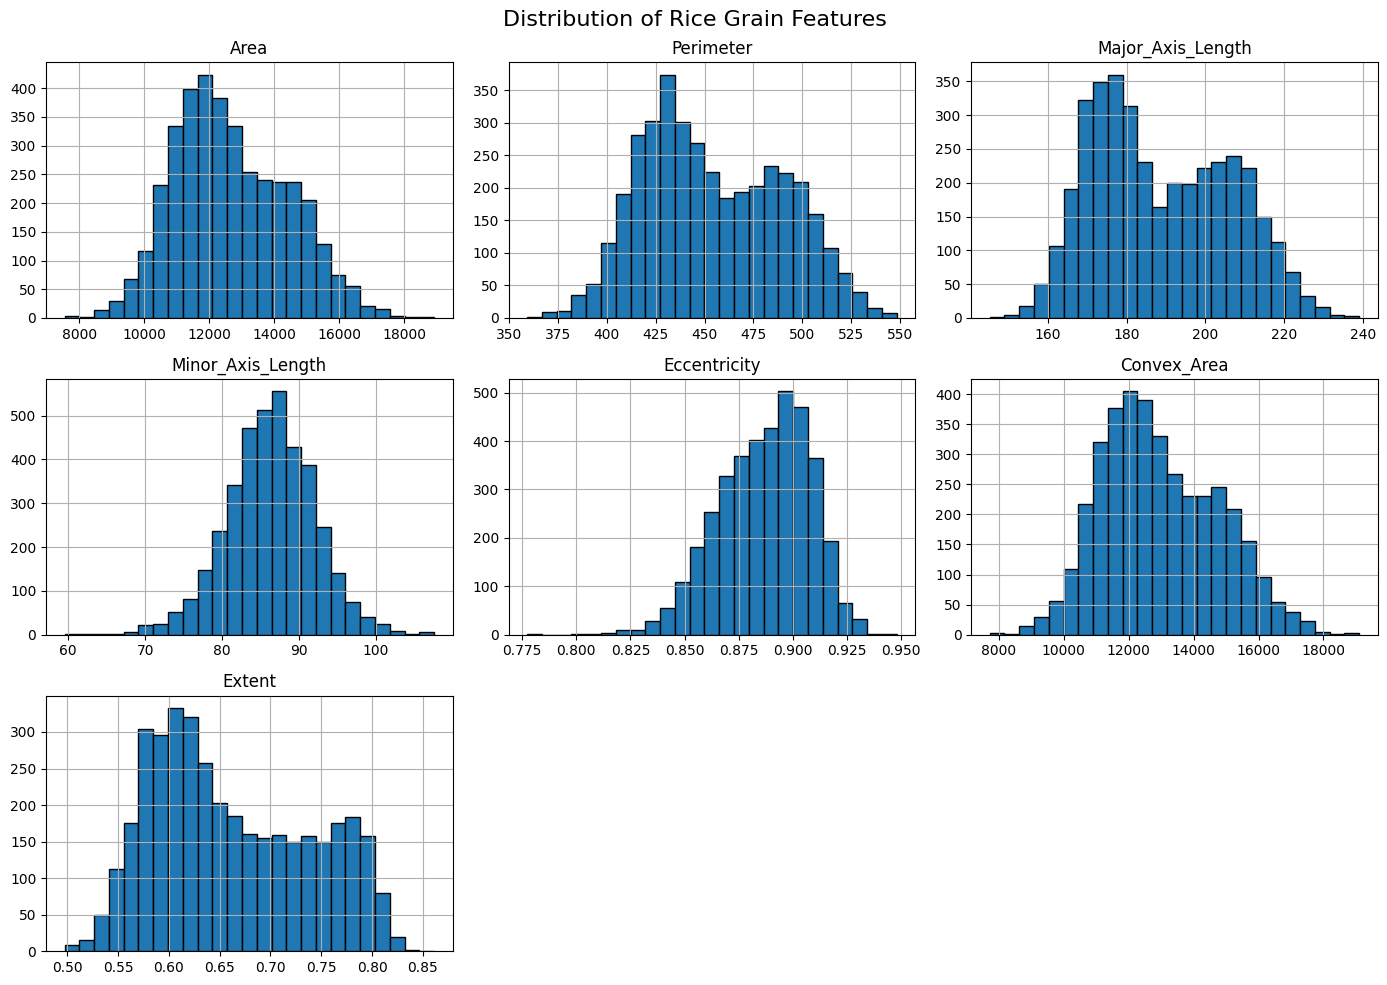

In [ ]:
df.hist(
    figsize=(14,10),
    bins=25,
    edgecolor='black'
)

plt.suptitle('Distribution of Rice Grain Features', fontsize=16)

plt.tight_layout()
plt.show()

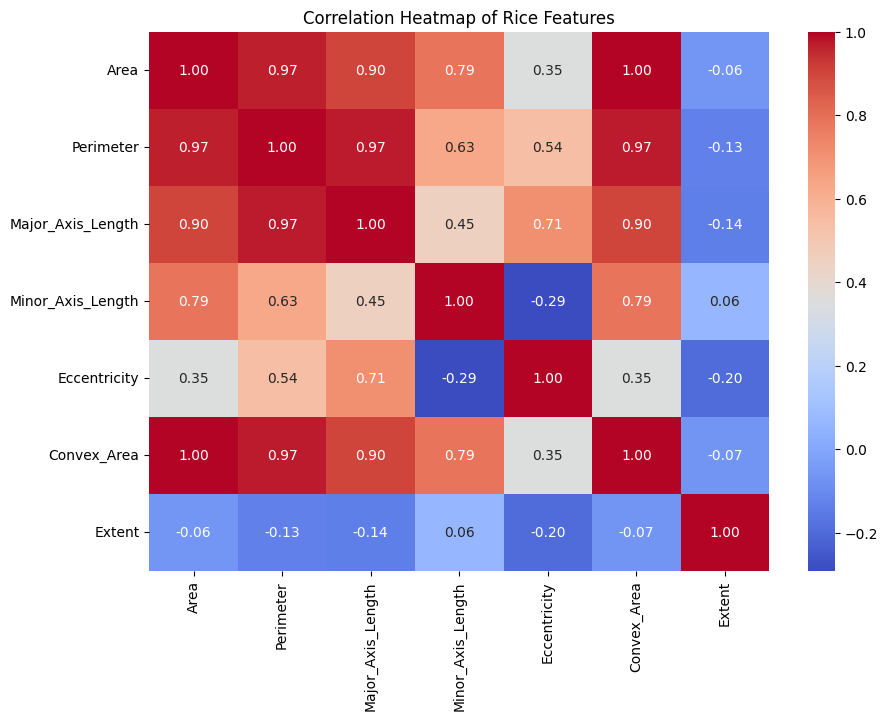

In [ ]:
plt.figure(figsize=(10,7))

correlation = df.drop(columns=['Class']).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Rice Features')

plt.show()

<Figure size 700x600 with 0 Axes>

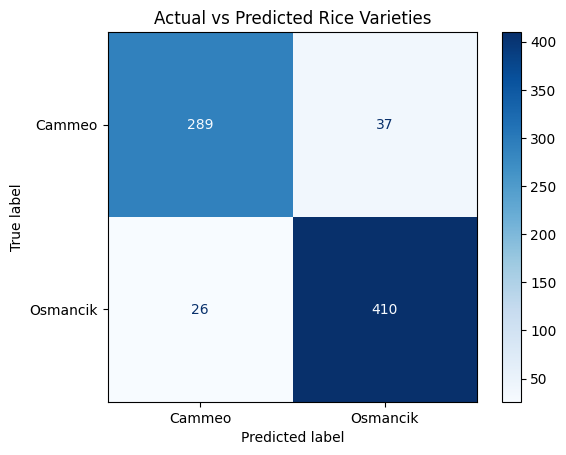

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=encoder.classes_,
    cmap='Blues'
)

plt.title('Actual vs Predicted Rice Varieties')

plt.show()

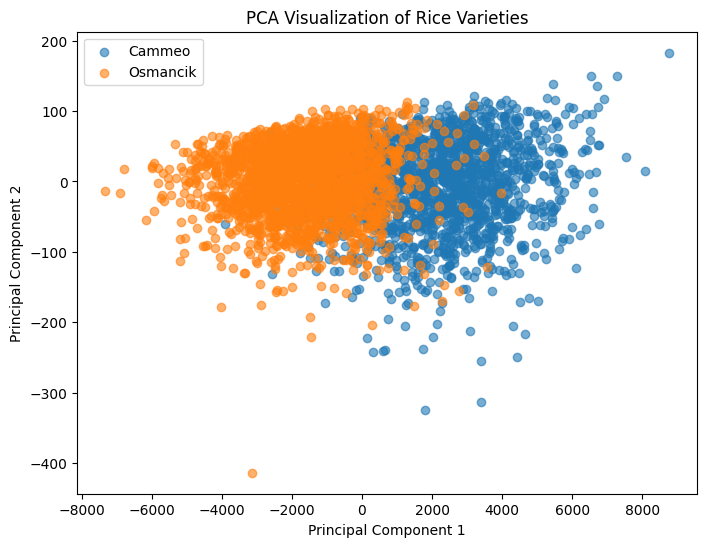

Explained variance: 99.99773327066015 %


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

plt.figure(figsize=(8,6))

for label in np.unique(y):

    plt.scatter(
        X_pca[y == label, 0],
        X_pca[y == label, 1],
        label=encoder.inverse_transform([label])[0],
        alpha=0.6
    )

plt.title('PCA Visualization of Rice Varieties')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

print("Explained variance:",
      pca.explained_variance_ratio_.sum() * 100, "%")

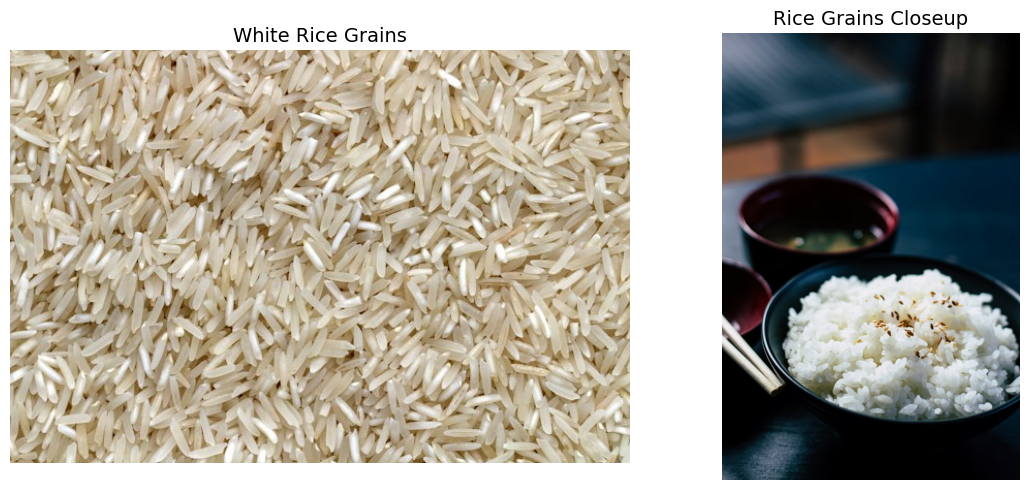

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Rice image URLs
image_urls = {
    "White Rice Grains": "https://images.unsplash.com/photo-1586201375761-83865001e31c?w=600",
    "Rice Grains Closeup": "https://images.unsplash.com/photo-1516684732162-798a0062be99?w=600"
}

plt.figure(figsize=(12, 5))

for i, (name, url) in enumerate(image_urls.items()):

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content))

    plt.subplot(1, 2, i+1)
    plt.imshow(img)
    plt.title(name, fontsize=14)
    plt.axis('off')

plt.tight_layout()
plt.show()

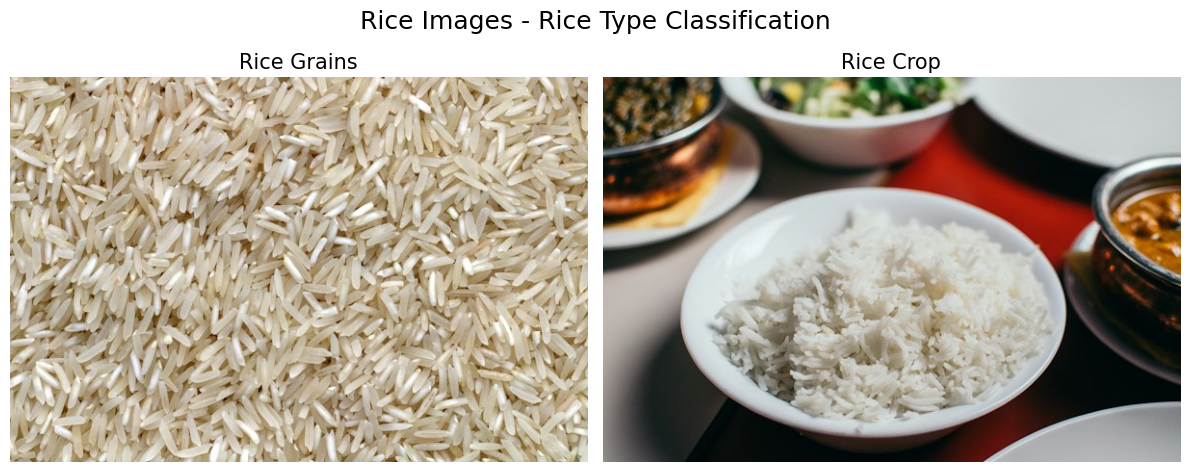

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

rice_images = [
    ("Rice Grains", "https://images.unsplash.com/photo-1586201375761-83865001e31c?w=600"),
    ("Rice Crop", "https://images.unsplash.com/photo-1536304993881-ff6e9eefa2a6?w=600")
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (title, url) in zip(axes, rice_images):

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content))

    ax.imshow(image)
    ax.set_title(title, fontsize=15)
    ax.axis("off")

plt.suptitle("Rice Images - Rice Type Classification", fontsize=18)
plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs("/content/rice_images", exist_ok=True)

for title, url in rice_images:

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    filename = title.replace(" ", "_") + ".jpg"

    with open("/content/rice_images/" + filename, "wb") as f:
        f.write(response.content)

print("Rice images saved successfully!")

Rice images saved successfully!
